In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

In [6]:
df = pd.read_csv('National_River_Toxin_Dataset_1.csv')
#data set was once again provided by ITOnlineLearning for the purpouses of this prjoect work.

#### 0.0 Profiling

In [7]:
df.head(15)

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925
5,2018-01-08,Amazon,6.816453,20.009290,2.317695,0.468534,2.779205,14.375101,NaN,8.801352
6,2018-01-08,Nile,7.713234,19.385417,3.281072,NaN,2.969543,8.043222,0.400075,7.887773
7,2018-01-08,Yangtze,6.997987,17.460123,5.077893,0.668969,6.103828,9.058403,0.667304,6.697805
8,2018-01-08,Mississippi,8.053054,20.636471,4.150143,0.629782,3.154285,8.761829,0.562562,8.981253
9,2018-01-08,Danube,7.552935,22.521190,2.779919,0.314452,2.232550,10.508599,0.534827,10.050782


We can already see some missing values in columns for Mercury and Phosphates. The are no clear indicators for what units are being used in this case, however going off this is a measurement of toxin in river systems we can comfortably assume that measurements are in **ppb** (part per billion) for *Lead, Mercury, Arsenic* and **ppm** (parts per million) for *Nitrates, and Phosphates* columns.
    We are also going to go off the assumption that temperatures are being measured in Celsius as this is the predominant measurment unit in the world.
    By the look of the Date column, we can assess that it is currently in Object dtype at this moment - naturally we will need to double check and in necessary conver to datetime for best efficiency of calculations of our analysis.

    Both of these point would usually be discussed in a meeting, but as this is a course project, we are going off of resonable diduction.

In [8]:
df.shape

(1305, 10)

we have 1305 records and 10 columns

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1305 non-null   object 
 1   River_System      1305 non-null   object 
 2   pH_Level          1278 non-null   float64
 3   Temperature       1278 non-null   float64
 4   Lead              1285 non-null   float64
 5   Mercury           1278 non-null   float64
 6   Arsenic           1279 non-null   float64
 7   Nitrates          1265 non-null   float64
 8   Phosphates        1282 non-null   float64
 9   Dissolved_Oxygen  1284 non-null   float64
dtypes: float64(8), object(2)
memory usage: 102.1+ KB


Date column will need to be converted into datetime.
We can also clearly see that we have quiet a few missing values across several columns - will needd to see just how much data is missing and what is the most appropriate way to handle it. Special care need to be put in, as this data deals with toxin levels in river systems, which affects both human and animal populations. We need addequate levels of data not to scew the results and an appropriate methodology for dealing with the NaN's in this data set.

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pH_Level,1278.0,7.353247,0.349114,6.465087,7.101324,7.339326,7.585733,8.392902
Temperature,1278.0,20.041668,4.063638,9.891618,16.813976,20.039121,23.358634,30.749449
Lead,1285.0,3.011035,0.874431,0.551349,2.366298,3.000714,3.676560,5.800963
Mercury,1278.0,0.596108,0.175150,0.157117,0.462683,0.599186,0.734863,1.057494
Arsenic,1279.0,3.597916,0.992052,1.485608,2.836160,3.511678,4.298946,6.232902
Nitrates,1265.0,10.038789,2.096641,2.025075,8.701188,10.089112,11.391686,16.547073
Phosphates,1282.0,0.497162,0.106304,0.144044,0.422006,0.497631,0.572888,0.870007
Dissolved_Oxygen,1284.0,8.023795,1.064190,5.041394,7.269386,8.007448,8.740828,11.228677


From this table we can clearly see that majority of our measures fall within normal distribution, appart from *Temperature, Nitrates* and *Dissolved_Oxygen*. All the same columns also have quiet a significant range. *Arsenic* too has quiet a significant range in its data.

In [11]:
df.tail(15)
#errors are most likely to happen at the end of a dataset, so we're checking to see if there are any additional errors that we havent spotted from out head.

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
1290,2022-12-12,Amazon,6.877583,14.299441,1.933806,0.370378,2.469326,7.978846,0.519508,NaN
1291,2022-12-12,Nile,7.579790,19.446072,2.424780,0.809189,4.074426,11.119942,0.554345,8.791764
1292,2022-12-12,Yangtze,7.313984,17.735321,5.180277,0.893061,5.538109,10.379475,0.324817,9.054887
1293,2022-12-12,Mississippi,7.605171,18.137570,3.991870,0.538509,3.161891,8.400547,0.453937,8.183113
1294,2022-12-12,Danube,7.330175,16.802852,2.381174,0.488967,2.227370,8.327064,0.363343,7.978580
1295,2022-12-19,Amazon,6.937871,19.325744,2.094279,0.383392,3.146109,8.602876,0.708177,7.097128
1296,2022-12-19,Nile,7.731742,19.931780,3.589843,0.668092,3.133161,10.485642,0.517996,6.989271
1297,2022-12-19,Yangtze,7.019395,21.368076,4.648503,NaN,4.930842,7.435971,0.572838,8.524499
1298,2022-12-19,Mississippi,7.427439,21.170012,3.775850,0.767132,3.167035,7.103071,NaN,7.816279
1299,2022-12-19,Danube,7.571116,18.117695,1.849847,0.468266,2.430705,10.405424,0.607075,8.920067


#### 0.1 Cleaning and Conversion

In [12]:
#checking for NaN's and health of the columns
countofnan = df.isna().sum()
percentofnan = df.isna().mean()

print(f'Count of NaN per column: {countofnan}\n')
print(f'Percentage of NaN per column: {percentofnan}')

Count of NaN per column: Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64

Percentage of NaN per column: Date                0.000000
River_System        0.000000
pH_Level            0.020690
Temperature         0.020690
Lead                0.015326
Mercury             0.020690
Arsenic             0.019923
Nitrates            0.030651
Phosphates          0.017625
Dissolved_Oxygen    0.016092
dtype: float64


**Percent Data Missing** 
pH_Level: **2%**, Temperature: **2%**, Lead: **1.5%**, Mercury: **2%**, Arsenic: **2%**, Nitrates: **3%**, Phosphates: **1.8%**, Dissolved_Oxygen: **1.6%**

In accordance with scientific standard, data missing **less than 5%** is **statistically insignificant**, with our largest percentage of missing data at 3% - we can confortably state that this will not cause major issues to our analysis. We are also going to assume that the errors in data had occured due to data logging at random  - human error.

According to best practices, when dealing with toxin levels, best way to deal with the at random missing data is though documented imputation - in this case we will be using median, in order not to scew the data as toxins are skewed due to spikes in exposure levels.

Once again this would usually be discussed in a meeting and questions would be asked off research team or their liason. 

#### Documentation of Imputation for NaN Values in the Data Set

In [13]:
#we are going to simplify the process of cleaning up our data and keeping a record of our imputations - as the purpouse of this project is the analysis more so than proper scientific data cleaning and record keeping process.
#specifying the columns we need to clean, and creating a clean columns summary variable.
pH_and_toxin_columns = ['pH_Level', 'Temperature', 'Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates', 'Dissolved_Oxygen']
cleaned_summary = []

#creating our for loop
for col in pH_and_toxin_columns:
    # counting the number of missing values and the percentage
    missing_count = df[col].isna().sum()
    missing_percent = (missing_count/len(df)) * 100

    #calculating the median, and then over writing the NaN values with the said median.
    col_median = df[col].median()
    df[col] = df[col].fillna(col_median)

    #recording the values in cleaned_summary
    cleaned_summary.append(
    {
    'Toxin Variable': col,
    'Missing Rows': missing_count,
    'Percent Missing': f'{missing_percent:.1f}',
    'Imputed Value - Median': f'{col_median:.2f}'
    }
    )

cleaned_summary_df = pd.DataFrame(cleaned_summary)

print('Summary of Cleaned Data of River Toxin Logs')
print(cleaned_summary_df.to_markdown(index=False))

Summary of Cleaned Data of River Toxin Logs
| Toxin Variable   |   Missing Rows |   Percent Missing |   Imputed Value - Median |
|:-----------------|---------------:|------------------:|-------------------------:|
| pH_Level         |             27 |               2.1 |                     7.34 |
| Temperature      |             27 |               2.1 |                    20.04 |
| Lead             |             20 |               1.5 |                     3    |
| Mercury          |             27 |               2.1 |                     0.6  |
| Arsenic          |             26 |               2   |                     3.51 |
| Nitrates         |             40 |               3.1 |                    10.09 |
| Phosphates       |             23 |               1.8 |                     0.5  |
| Dissolved_Oxygen |             21 |               1.6 |                     8.01 |


In [14]:
#double checking for NaN's after the clean
countofnan = df.isna().sum()
percentofnan = df.isna().mean()

print(f'Count of NaN per column: {countofnan}\n')
print(f'Percentage of NaN per column: {percentofnan}')

Count of NaN per column: Date                0
River_System        0
pH_Level            0
Temperature         0
Lead                0
Mercury             0
Arsenic             0
Nitrates            0
Phosphates          0
Dissolved_Oxygen    0
dtype: int64

Percentage of NaN per column: Date                0.0
River_System        0.0
pH_Level            0.0
Temperature         0.0
Lead                0.0
Mercury             0.0
Arsenic             0.0
Nitrates            0.0
Phosphates          0.0
Dissolved_Oxygen    0.0
dtype: float64


We have now confirmed that we have successfully cleaned up our data

0       False
1       False
2       False
3       False
4       False
        ...  
1300    False
1301    False
1302    False
1303    False
1304    False
Length: 1305, dtype: bool

No duplicates detected in our dataframe.

In [16]:
#transforming Date column into datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

#double checking the conversion
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              1305 non-null   datetime64[ns]
 1   River_System      1305 non-null   object        
 2   pH_Level          1305 non-null   float64       
 3   Temperature       1305 non-null   float64       
 4   Lead              1305 non-null   float64       
 5   Mercury           1305 non-null   float64       
 6   Arsenic           1305 non-null   float64       
 7   Nitrates          1305 non-null   float64       
 8   Phosphates        1305 non-null   float64       
 9   Dissolved_Oxygen  1305 non-null   float64       
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 102.1+ KB


We can also see that we have all 1305 records filled across the whole data set and our Date column is now in correct dtype.

In [21]:
#establishing timeline for our data set through arranging it by date earliest to latest
dates_recorded = df['Date'].sort_values()
print(dates_recorded)

0      2018-01-01
1      2018-01-01
2      2018-01-01
3      2018-01-01
4      2018-01-01
          ...    
1302   2022-12-26
1303   2022-12-26
1300   2022-12-26
1301   2022-12-26
1304   2022-12-26
Name: Date, Length: 1305, dtype: datetime64[ns]


Our established timeline - 1st of Jan 2018 to 26th of Dec 2022.

#### 0.1 Determining Toxin of Focus

In our data set we have several toxins - meaning we need to determine a toxin to focus on. For purpouses of promoting concervation efforts the most appropriate candidates are: Nitrates and Phosphates, and Mercury. Nitrates and Phostphates due to legislatively crealer path to systematic reform. While Mercury is a hightly toxic heavy metal that is dangerous for human and animal alike - this is more usedull in international level of reform of enviromental polution.

To decide which of these are the most appropriate for our use, we will be comparing the levels recorded in our data against the EU legistated safety levels for each of these toxins.

*Once again, in a regular environment this would be decided with the team that we (I, the analyst) is working with as well as the team of reseachers/their laison/organisation that have conducted the research.*

According to documentation of EU regulations (Directive 2006/118/EC of the European Parliament and of the Council of 12 December 2006 on the prevention and control of groundwater pollution) the safe thresholds are:

Nitrates : 50 ppm (mg/L)
Phosphates : 0.05 - 0.1 ppm (mg/L)
Mercury : 0.07 ppb (ug/L)

We can then also compare or describe() breakdown of our data and compare the limits in the legislation again the min and max recorded values.
From this comparison we can then exclude Nitrates **(min: 2.02, max: 16.55)** and Phosphates **(min: 0.14, max: 0.87)** as both are within the regulated safety limits. However we can add Lead to out threshold testing, Lead **(min:0.55, max: 3.68)**

Safe threshold for Lead in accordance with EU Directive:

Lead : 1.2 ppb (ug/L)

In [22]:
#creating a dict of safety thresholds for out two toxins
safety_limits = {
    'Lead': 1.2,
    'Mercury': 0.07
}
decision_metrics = []

#creating the for loop to go through our toxin columns and calculate howmany data points go above the threshold
for toxin, limit in safety_limits.items():
    exceeded_count = (df[toxin] > limit).sum()
    rate_exceeded = (exceeded_count/len(df))*100

    #we will be calculating the hazard for our toxins. Hazard=(Exposure concentration/Effect concentration)
    hazard = df[toxin]/limit
    avg_hazard = hazard.mean()
    max_hazard = hazard.max()

    #we now logg our diagnostics into the decision_metrics variable
    decision_metrics.append(
    {
    'Toxin' : toxin,
    'Safety_Limit' : limit,
    'Count of Exceeded Records' : exceeded_count,
    'Rate of Exceeded Records' : f'{rate_exceeded:.1f}%',
    'Average Hazard Severity' : f'{avg_hazard:.2f}x',
    'Max Spike of Hazard Severity' : f'{max_hazard:.2f}x'
    }
    )

#as previously we are converting our dict list into a reporting table
decision_summary_df = pd.DataFrame(decision_metrics)

print('Hazard Asessment Matric for Toxin Decision Making')
print(decision_summary_df.to_markdown(index=False))

Hazard Asessment Matric for Toxin Decision Making
| Toxin   |   Safety_Limit |   Count of Exceeded Records | Rate of Exceeded Records   | Average Hazard Severity   | Max Spike of Hazard Severity   |
|:--------|---------------:|----------------------------:|:---------------------------|:--------------------------|:-------------------------------|
| Lead    |           1.2  |                        1286 | 98.5%                      | 2.51x                     | 4.83x                          |
| Mercury |           0.07 |                        1305 | 100.0%                     | 8.52x                     | 15.11x                         |


From this result - we would usually conduct another meeting and discuss what toxin to pursue. In this case going off the directions given for the project, we will focus the study on Mercury levels, as this is (as previously mentioned) the toxin most commonly used by environmental groups in pursuing ecological changes in interantional legislation.

#### 1.0 Toxisity Levels of Mercury in River Systems

In [23]:
#calculation avg lead and Mercury levels per rivery system
avg_mercury_per_riversystem = df.groupby('River_System')['Mercury'].median().sort_values(ascending=False).round(2)

print('Average Levels of Mercury in ppb (ug/L)')
print(f'{avg_mercury_per_riversystem}')

Average Levels of Mercury in ppb (ug/L)
River_System
Yangtze        0.79
Nile           0.70
Mississippi    0.60
Amazon         0.49
Danube         0.40
Name: Mercury, dtype: float64


With established legislative limit on Mercury being **0.07** ppb - it is clear to see that *all* of the river systems in our data set are *significantly* affected by it's contamination. With the highest average levels of **0.79** recorded are in Yangtze River located in China. With the lowest levels recorded in Danube River located in Germany, with average Mercury levels recorded **0.40**.
These levels a far above the recomended safe levels of heavy metals in water ways. 

In [29]:
#because our objective is to compaire toxin levels in two major river systems - we know that we need to perform the two-sample t-test

#filtering our river systems by the top two rivers as seen in average calculation above.
yangtze_river = df[df['River_System'] == 'Yangtze']['Mercury']
nile_river = df[df['River_System'] == 'Nile']['Mercury']

t_stat, p_val = stats.ttest_ind(yangtze_river, nile_river)

print(f't-test Statistics: {t_stat:.4f}')
print(f'p-value Statistics: {p_val:.4f}')

t-test Statistics: 8.8344
p-value Statistics: 0.0000


From our t-test result of **8.8344** we can conclude that there is a significant difference in the averages between Yangze and Nile rivers - we can also see that in our averages calculations in the section above.
p-value sitting at below 0.0001 lends to conclution of the two rivers different toxin levels being statistically significant - meaning  if we gain the two samples one from each river, we can be confident that the sample with highter levels of Mercury will be coming from Yangtze river.

##### 1.1 pH in River Systems Correlation with Toxin (Mercury) exposure

In [30]:
#calculating the correlation between pH and Mercury levels in the water systems
pH_Mercury_correlation = df['pH_Level'].corr(df['Mercury'],method= 'spearman')

print('Correlation of pH Levels and Recorded Level of Mercury in River Systems')
print(f'{pH_Mercury_correlation:.2f}')

Correlation of pH Levels and Recorded Level of Mercury in River Systems
0.14


Looking at positive correlation we can constitute that pH level rise (the water ways become more alkaline) with higher detected Mercury levels - however not at a very significant level. With the correlation at **0.14** we can conclude that though statistically neglegend there is a likelyhood that this event occures due to industrial dumping (as natural levels of heavy metals tend to have *negative* correlation). The low number, closer to zero, lets us know that this is likely done on an disorganised, isolated basis and not a systematic issue.

We are using Spearman correlation method due to the nature of toxicological studies e.g. working with data with heavy skewness. 

##### 1.2 Yearly Threshold Analysis 

In [50]:
#to see the trend of toxin levels (mercury) across time, since we have 5 years in our data - we'll be looking at the trends across years.
#create a Year and Month column
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

#grouping our mercury levels by median (as this will not be affected by the spikes in our data meaning on a low level of granularity), and we will be capturing the max - in order to see the spikes in out toxin levels.
yearmonth_mercury_levels_summary = df.groupby(['Year', 'Month'])['Mercury'].agg(['median', 'max']).round(2)

#converting the averages and spikes into the hazard quotient
yearmonth_hq = (yearmonth_mercury_levels_summary/0.07).round(1)

#to make the result ledgeable
#flattening the yearmonth_hq table
flatt_yearmonth_hq = yearmonth_hq.reset_index()

#converting numeric months to short form month names
month_name = {
    1: 'Jan',
    2: 'Feb',
    3: 'Mar',
    4: 'Apr',
    5: 'May',
    6: 'Jun',
    7: 'Jul',
    8: 'Aug',
    9: 'Sep',
    10: 'Oct',
    11: 'Nov',
    12: 'Dec'
}

#maping the short form name onto autogenerated month numbers.
flatt_yearmonth_hq['Month'] = flatt_yearmonth_hq['Month'].map(month_name)

#change the column names into readable options
flatt_yearmonth_hq.columns = [
    'Year',
    'Month',
    'Recorded Baseline (Median HQ)',
    'Recorded Accute Increase (Max HQ)'
]

print('Cronological Mercury Threshold (0.07 ppb (ug/L)) Analysis for 2018 - 2022')
print(flatt_yearmonth_hq.to_markdown(index=False))

Cronological Mercury Threshold (0.07 ppb (ug/L)) Analysis for 2018 - 2022
|   Year | Month   |   Recorded Baseline (Median HQ) |   Recorded Accute Increase (Max HQ) |
|-------:|:--------|--------------------------------:|------------------------------------:|
|   2018 | Jan     |                             8.6 |                                13.4 |
|   2018 | Feb     |                             8.7 |                                13.6 |
|   2018 | Mar     |                             8.9 |                                12   |
|   2018 | Apr     |                             8.4 |                                12.7 |
|   2018 | May     |                             9.3 |                                11.7 |
|   2018 | Jun     |                             8.3 |                                12.3 |
|   2018 | Jul     |                             8.4 |                                12.1 |
|   2018 | Aug     |                             7.9 |                                14.

#### 2.0 Visualisations

##### 2.1 Globaly Recorded Median-Average Recorded Mercury Levels in ppb (ug/L) by Year, 2018 - 2022

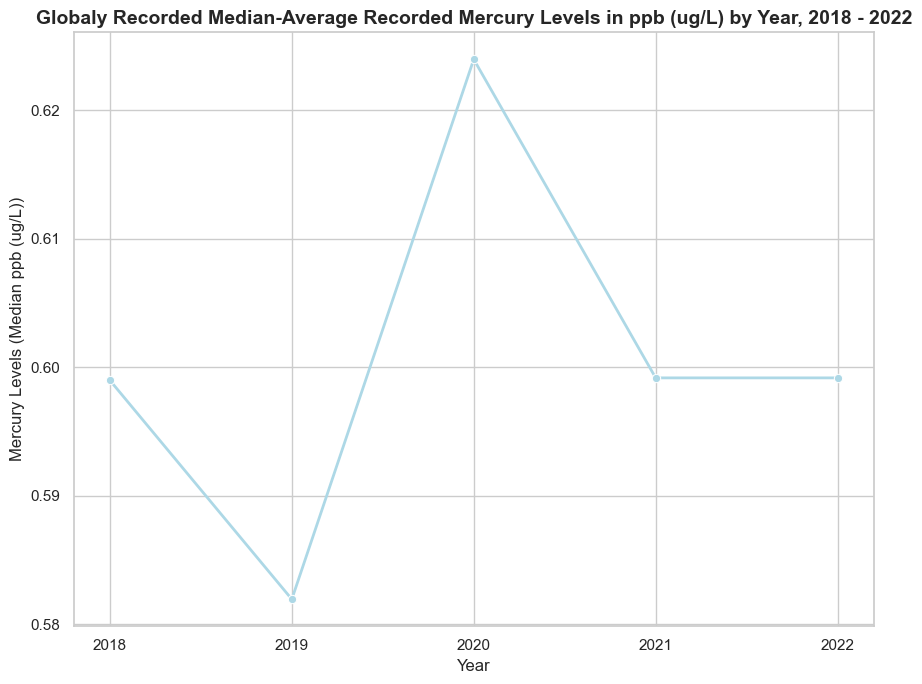

In [58]:
#grouping Mercury levels my year
mercury_by_monthyear = df.groupby(['Year'])['Mercury'].median().reset_index()

#need to convert year column to string for ploting
mercury_by_monthyear['Year'] = mercury_by_monthyear['Year'].astype(str)

#setting up a clean grid
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9,7))

ax = sns.lineplot(
    data=mercury_by_monthyear, 
    x='Year', 
    y='Mercury', 
    color='lightblue',
    marker= 'o',
    linewidth= 2
)

plt.title('Globaly Recorded Median-Average Recorded Mercury Levels in ppb (ug/L) by Year, 2018 - 2022', fontsize= 14, weight= 'bold')
plt.xlabel('Year', fontsize= 12)
plt.ylabel('Mercury Levels (Median ppb (ug/L))', fontsize= 12)

plt.tight_layout()
plt.show()

##### 2.2 Median-Average Recorded Mercury Levels in ppb (ug/L) by Year, 2018 - 2022

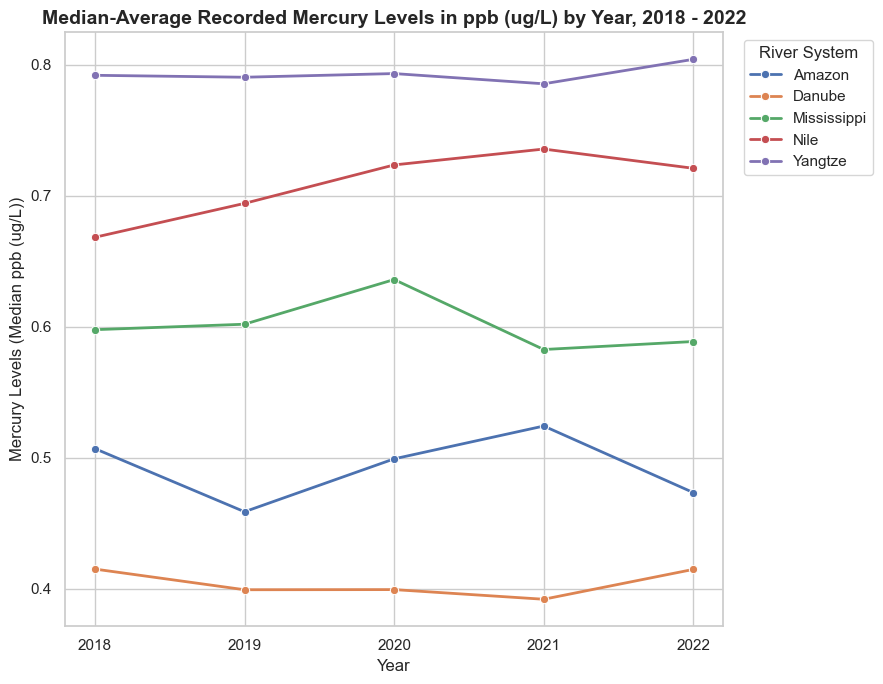

In [57]:
#grouping Mercury levels my year\
mercury_by_monthyear = df.groupby(['River_System', 'Year'])['Mercury'].median().reset_index()

#need to convert year column to string for ploting
mercury_by_monthyear['Year'] = mercury_by_monthyear['Year'].astype(str)

#setting up a clean grid
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9,7))

ax = sns.lineplot(
    data=mercury_by_monthyear, 
    x='Year', 
    y='Mercury', 
    hue= 'River_System',
    color='lightblue',
    marker= 'o',
    linewidth= 2
)

plt.title('Median-Average Recorded Mercury Levels in ppb (ug/L) by Year, 2018 - 2022', fontsize= 14, weight= 'bold')
plt.xlabel('Year', fontsize= 12)
plt.ylabel('Mercury Levels (Median ppb (ug/L))', fontsize= 12)

plt.legend(title= 'River System', bbox_to_anchor= (1.02, 1), loc= 'upper left')

plt.tight_layout()
plt.show()

##### 2.3 Median-Average Detected Mercury Levels (ppb (ug/L)) Across River Systems

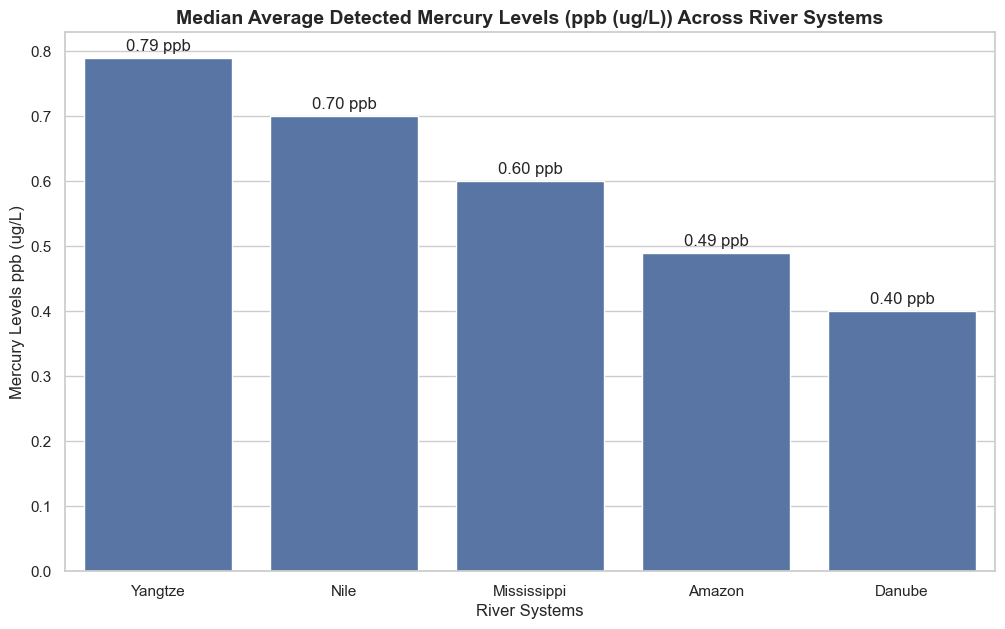

In [59]:
#grouping toxin levels by river system
avg_mercury_per_riversystem = df.groupby('River_System')['Mercury'].median().sort_values(ascending=False).round(2).reset_index()

#setting up the line graph
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12,7))

ax = sns.barplot(
    data=avg_mercury_per_riversystem,
    x='River_System',
    y='Mercury'
)

ax.bar_label(ax.containers[0], fmt= '%.2f ppb', padding=3)

plt.title('Median Average Detected Mercury Levels (ppb (ug/L)) Across River Systems', fontsize= 14, weight= 'bold')
plt.xlabel('River Systems', fontsize= 12)
plt.ylabel('Mercury Levels ppb (ug/L)', fontsize= 12)

plt.show()

##### 2.4 Toxicologival Correlation Heatmap: Water pH and Contaminant Levels

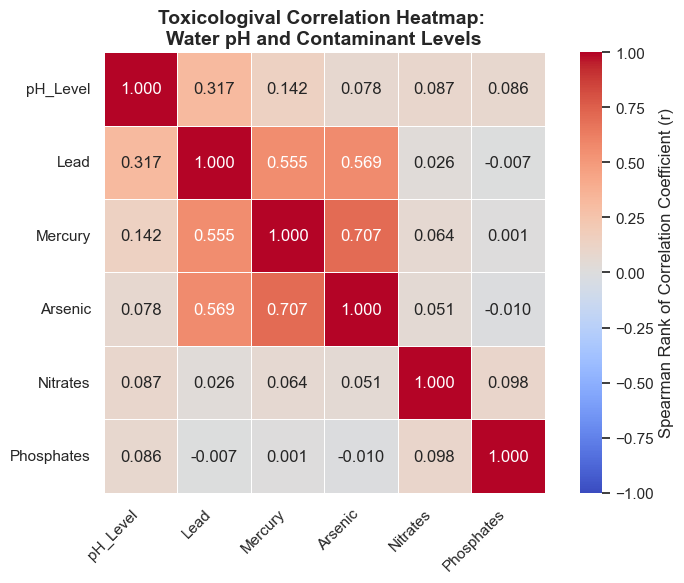

In [34]:
#selecting our variables to easier calculate the correlations
analysis_vars = ['pH_Level', 'Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates']

#creating our correlation matrix
corr_matrix_pH_v_toxins = df[analysis_vars].corr(method= 'spearman')

sns.set_theme(style='white')
plt.figure(figsize=(8,6))

#the heatmap
ax = sns.heatmap(
    data= corr_matrix_pH_v_toxins,
    annot= True,
    fmt= '.3f',
    cmap= 'coolwarm',
    vmin= -1,
    vmax= 1,
    linewidth= 0.5,
    square= True,
    cbar_kws= {'label': 'Spearman Rank of Correlation Coefficient (r)'}
)

plt.title('Toxicologival Correlation Heatmap: \nWater pH and Contaminant Levels', fontsize= 14, weight= 'bold')

plt.xticks(rotation= 45, ha= 'right')
plt.yticks(rotation= 0)

plt.tight_layout()
plt.show()

In [61]:
#creating linear regression of Mercury levels based on pH
X= df[['pH_Level']]
Y= df['Mercury']

model= LinearRegression()
model.fit(X, Y)

print(f'Linear Regression Coeffitient of Mercury based on pH levels: {model.coef_[0]:.4f}')
print(f'Linear Regression Intercept of Mercury Based on pH levels: {model.intercept_:.4f}')

Linear Regression Coeffitient of Mercury based on pH levels: 0.0691
Linear Regression Intercept of Mercury Based on pH levels: 0.0884


With pH Levels being the dependant variable, according to our calculation for every level the pH of water goes up, we can predict that Mercury levels will go up by 0.069 ppb (ug/L) - with sade threshold for mercury at 0.07 ppb (ug/L), this constitutes dangerous levels of toxicity.

In [35]:
#first off we need to convert our month column into seasons
month_to_season = {
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Autumn',
    10: 'Autumn',
    11: 'Autumn',
    12: 'Winter'
}

#we map our seasons onto the months - creating a Seasons column to use in the boxplot
df['Season'] = df['Month'].map(month_to_season)

#double checking it works as intended
print(df[['Year', 'Month', 'Season']].head())
print(df[['Year', 'Month', 'Season']].tail())

   Year  Month  Season
0  2018      1  Winter
1  2018      1  Winter
2  2018      1  Winter
3  2018      1  Winter
4  2018      1  Winter
      Year  Month  Season
1300  2022     12  Winter
1301  2022     12  Winter
1302  2022     12  Winter
1303  2022     12  Winter
1304  2022     12  Winter


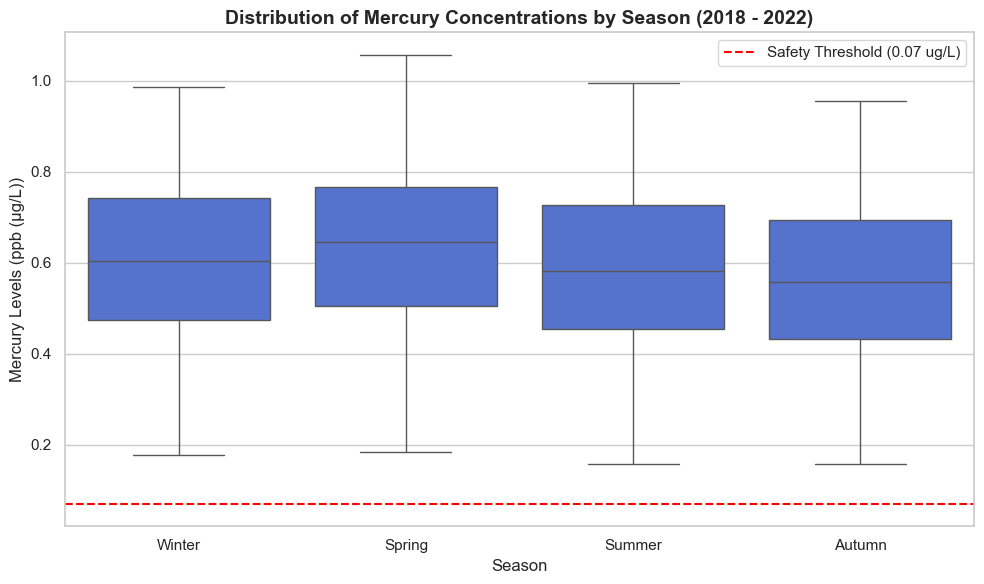

In [36]:
#setting up the boxplot
sns.set_theme(style= 'whitegrid')
plt.figure(figsize=(10, 6))

#clearifying our order for the x=axis
seasons = ['Winter', 'Spring', 'Summer', 'Autumn']

#boxplot
sns.boxplot(
    data= df,
    x= 'Season',
    y= 'Mercury',
    order= seasons,
    color= 'royalblue'
)

#adding a dashed red reference line for the safety threshold
safety_limit= 0.07
plt.axhline(
    y= safety_limit,
    color= 'red',
    linestyle= '--',
    linewidth= 1.5,
    label= f'Safety Threshold ({safety_limit} ug/L)',
)

# Formatting labels and titles
plt.title('Distribution of Mercury Concentrations by Season (2018 - 2022)', fontsize= 14, weight= "bold")
plt.xlabel('Season', fontsize=12)
plt.ylabel('Mercury Levels (ppb (µg/L))', fontsize=12)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

#### 3.0 Data Integrity and Constraints Sign-Off 

##### NaN Value Handling

With values missing across *pH_Level, Temperature, Lead, Mercury, Arsenic, Nitrates, Phosphates, Dissolved_Oxygen* columns, and the highest percentage of missing data laying at **3%** - according to statistic toxicological standard (**< 5%** missing data is acceptable) it is a negliable ammount missing. With the missing data being caused by human error, decition has been made to has been made that a median imputation is the best course of action. Clear documentation of which columns were altered, the count of data points altered, the total percent of data points altered, and the value entered in place of the previously missing values.

##### Outlier Retention

As we are dealing with levels of toxicity in River Systems, in line with toxicological standards, we have retained the outliers. As the spikes in toxin levels are significant for the purpouses of ecological concervation studies.

##### Data Types

Date column was altered to datetime dtype.

##### Determining Toxin of Focus

From the wide range of toxins in our data set, we had three toxins **Mercury, Nitrates, Phosphates** that are on the forefront of ecological legislative changes. We also looked at the ranges of toxins in our data set and from the range we had made the addition of **Lead** to our list. We then cross referenced our average recorded levels with legislated safety thresholds as set in Directive 2006/118/EC of the European Parliament and of the Council of 12 December 2006 on the prevention and control of groundwater pollution.
    With Nitrates and Phosphates being well within legal limit, we then calculated the Hazard Quotient (*Hazard=Exposure concentration/Effect concentration*) along with the count of limit exceeding records, the rate of exceeding records, the average hazard records and the spikes of hazard. Through this we could then compare the two remaining toxin, finally deciding to focus on Mercury with its average hazard severity of **8.52x** the safety limit, and the max hazard severity recorded sitting at **15.11x** the set safety limit.

#### 3.1 Exploration: Comparison and Relationships

##### Geographical Distiction (River vs Toxin)

Through calculating average levels of Mercury found in our monitored river systems - the top two systems with highest recorged levels were **Yangtze** located in China and **Nile** located in Egypt. Through testing, it can be concluded that Yangtze has a statistically higher baseline of Mercury contamination.

##### Contamination and pH Relationships

Through calculation and mapping the relationship between pH and Mercury we can see a low level of correlation between the two, per one unit of pH going up, Mercury levels uptick **0.0691** ppb (parts per billion). **Safety Threshold** for Mercury in rivers, accoring EU legislation, is **0.07** ppb.

#### 3.2 Inferential Analysis

##### Test A: Independant Two-Sample t-test

Dependant variable: pH levels 
Independant variable: Merucy levels

Metrics: t-test Statistics: **8.8344** p-value Statistics: **0.0000**

Outcome: the t-test results constitute that the two examined bodies of water are vastly distinct in their contamination levels. The exceptionally low p-value strenthens this distiction, with statistical cetainty.

##### Test B: Simple Linnear Regression

Objective: Measure the predictibility toxin contamination of water with use of pH levels as predictors

Metrics: Linear Regression Coeffitient of Mercury based on pH levels: **0.0691**

Outcome: Coeffitient confirms elevated Mercury levels when water measures alkaline. For every one unit increace of pH, Mercury levels are elevated by **0.0691** - constituting dangerous levels of toxicity.

#### 3.3 Conclusions

##### High Base Levels of Mercury in Monitored River Systems

All five monitored river systems are recorded to have Mercury levels far exceeding the legal safe limit of 0.07ppb (ug/L) as set by EU Directive 2006/118/EC of the European Parliament and of the Council of 12 December 2006 on the prevention and control of groundwater pollution. Two major systems with the highest average levels of Mercury are **Yangtze: 0.79 ppb** and **Nile: 0.70 ppb**

##### Toxin Trends Across Time

We can see steady elevated levels of Mercury across our river systems, on average none of the systems have a conciderate spikes as seen in *Median-Average Recorded Mercury Levels in ppb (ug/L) by Year, 2018 - 2022*. Across all five rivers toxin levels go up dramatically during 2020 **0.62** and then dropping down to average **0.60**

##### Seasonality of Mercury in River Systems for 2018 - 2022

Across the recorded years of 2018 - 2022, we can see clear seasonality in spikes of toxic exposure during **Winter (December, January, February)** and **Spring (March, April, May)** months. Though toxicity on the overal are at a dangerous level range between **0.16 and 1.06 ppb**

##### Correlation Coefficient(s) of Toxin and pH Levels

Through mapping the pH levels across all the recorded toxins we can see strong correlation between alkalisation of the water systems and **Mercury: 0.14 ppb and Lead 0.32 ppb**. 

#### 4.0 Summary

By looking over the base contamination levels of the systemns we can see that overal toxicity levels are of a large scale, with all monitored rivers systems **Yangtze: 0.79 ppb, Nile: 0.70 ppb, Mississippi: 0.60 ppb, Amazon: 0.49 ppb, Danube 0.40 ppb** far above the safety threshold of 0.07 ppb. These levels combined with the low correlation of high pH and elevation in Mercury we can constitute that the likelyhood of large scale systematic chemical dumping is low - however investigation of industrial activity would be advisable. With clear uptake of toxin levels in the **winter (December, January, Febriary) and spring (March, April, May)** months close monitoring should take place suring this period of time.

In accordance with toxicological correlation map we can see that there is a strong correlation between **Lead, Mercury and Arcenix**, along with results of our simple linear regression, we can comfortably say that for every one unit of elevated pH, Mercury goes up by 0.69 ppb - with correlation between **0.56 to 0.7** there is a strong statistical certainty that **Lead and Arcenic** will be found in the water as well. A study of industries using these chemicals in the reagion(s) should be conducted and if local legislature allows they should be audited.

The effects of toxin exposure in the local wild life and population need to be documented and compiled to strengthen the case for stronger regulatory restrictions on industrial waste disposal.

A deep look into national and local legislature needs to be conducted in order to navigate and pin-point stragety for regulatory change.